<center><h1>Tabora_Jazmmine_HW7</h1></center>

Name: Jazmine Paulette Tabora
<br>
Github Username: JazmineTabora
<br>
USC ID: 8556136737

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, hamming_loss, silhouette_score
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv("Anuran Calls (MFCCs)/Frogs_MFCCs.csv")

In [3]:
# Choosing 70% of the data randomly as the training set
train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=552
)

In [4]:
print("Full dataset:", df.shape)
print("Training set:", train_df.shape)
print("Test set:", test_df.shape)

Full dataset: (7195, 26)
Training set: (5036, 26)
Test set: (2159, 26)


### (b) Train a classifier for each label

#### (i) Research

From researching, I gathered that exact match is for counting a prediction as correct when all three labels match the true labels for an observation. I also found that hamming loss tells us the proportion of labels that were predicted incorrectly for all obervations. For example, if an observation had 2 correct labels and 1 incorrect one, then it would contribute 1/3 to the loss. A hamming score is $1 - Hamming Loss$ which is the proportion of correctly predicted individual labels.

#### (ii) Train a SVM for each of the labels

In [9]:
feature_cols = [col for col in df.columns if col.startswith("MFCCs_")] 
target_cols = ["Family", "Genus", "Species"]

X_train = train_df[feature_cols]
y_train = train_df[target_cols]

X_test = test_df[feature_cols]
y_test = test_df[target_cols]

In [10]:
print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training labels:", y_train.shape)

Training features: (5036, 22)
Test features: (2159, 22)
Training labels: (5036, 3)


In [14]:
param_grid = {
    "estimator__C": [10, 100],
    "estimator__gamma": [1, 10]
}

svm_grids = {}

# training and tuning a separate SVM for each target variable
for target in target_cols:
    svm = OneVsRestClassifier(SVC(kernel="rbf"))   # Gaussian (RBF) SVM with one-vs-rest classification

    grid = GridSearchCV(
        estimator=svm,
        param_grid=param_grid,
        cv=10,   # 10-fold cross-validation
        scoring="accuracy"
    )

    grid.fit(X_train, y_train[target])
    svm_grids[target] = grid

In [15]:
print(svm_grids.keys())

for target, grid in svm_grids.items():
    print(target)
    print("Best parameters:", grid.best_params_)
    print("Best 10-fold CV accuracy:", grid.best_score_)
    print()

dict_keys(['Family', 'Genus', 'Species'])
Family
Best parameters: {'estimator__C': 100, 'estimator__gamma': 1}
Best 10-fold CV accuracy: 0.9914599703367099

Genus
Best parameters: {'estimator__C': 100, 'estimator__gamma': 1}
Best 10-fold CV accuracy: 0.9902706775221686

Species
Best parameters: {'estimator__C': 10, 'estimator__gamma': 1}
Best 10-fold CV accuracy: 0.9904698791378712



In [16]:
svm_predictions = pd.DataFrame(index=y_test.index)

for target in target_cols:
    svm_predictions[target] = svm_grids[target].predict(X_test)

# Exact match: all three labels must be correct for a row to count
exact_match = (svm_predictions == y_test).all(axis=1).mean()

# Hamming loss: fraction of individual labels predicted incorrectly
hamming_loss_value = (svm_predictions != y_test).to_numpy().mean()

# Hamming score: fraction of individual labels predicted correctly
hamming_score = 1 - hamming_loss_value

print("Test exact match:", exact_match)
print("Test Hamming score:", hamming_score)
print("Test Hamming loss:", hamming_loss_value)

Test exact match: 0.9823992589161649
Test Hamming score: 0.9890381349390149
Test Hamming loss: 0.010961865060985024


The 10-fold cross-validation selected $C = 100$, $\gamma = 1$ for Family and Genus and then $C=10$ and $\gamma=1$ for Species. The CV accuracy for Family was 99.15%, 99.03% for Genus, and 99.05% for Species.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [18]:
l1_param_grid = {
    "classifier__estimator__C": [0.01, 0.1, 1, 10, 100]
}
l1_svm_grids = {}

for target in target_cols:

    l1_pipeline = Pipeline([
        ("scaler", StandardScaler()),   # Standardize features within each CV fold
        ("classifier", OneVsRestClassifier(
            LinearSVC(penalty="l1", dual=False, max_iter=10000)  # fit an L1 linear SVM
        ))
    ])

    grid = GridSearchCV(
        estimator=l1_pipeline,
        param_grid=l1_param_grid,
        cv=10,   # 10-fold cross-validation to choose best C
        scoring="accuracy"
    )

    grid.fit(X_train, y_train[target])

    l1_svm_grids[target] = grid
    print(target)
    print("Best parameters:", grid.best_params_)
    print("Best 10-fold CV accuracy:", grid.best_score_)
    print()

l1_predictions = pd.DataFrame(index=y_test.index)

for target in target_cols:
    l1_predictions[target] = l1_svm_grids[target].predict(X_test)

# Exact match: all three labels must be correct for a row to count
l1_exact_match = (l1_predictions == y_test).all(axis=1).mean()

# Hamming loss: fraction of individual labels predicted incorrectly
l1_hamming_loss = (l1_predictions != y_test).to_numpy().mean()

# Hamming score: fraction of individual labels predicted correctly
l1_hamming_score = 1 - l1_hamming_loss

print("Test exact match:", l1_exact_match)
print("Test Hamming score:", l1_hamming_score)
print("Test Hamming loss:", l1_hamming_loss)

Family
Best parameters: {'classifier__estimator__C': 1}
Best 10-fold CV accuracy: 0.9386443245290165

Genus
Best parameters: {'classifier__estimator__C': 10}
Best 10-fold CV accuracy: 0.9539366972766574

Species
Best parameters: {'classifier__estimator__C': 10}
Best 10-fold CV accuracy: 0.9586989964972072

Test exact match: 0.9170912459471978
Test Hamming score: 0.9473521692141423
Test Hamming loss: 0.05264783078585765


The standardized L1-penalized linear SVM selected $C=1$ for Family, and $C=10$ for both Genus and Species from 10-fold cross-validation. The CV accuracy for Genus was 93.86%, 95.39% for Genus, and 95.87% for Species. The exact match was 91.71%, the hamming score was 94.74%, and the hamming loss was about 5.26%. The Gaussian SVM performed better.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [28]:
balanced_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

balanced_svm_grids = {}

In [29]:
for target in target_cols:

    # class_weight="balanced" gives more weight to less common classes
    balanced_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LinearSVC(
            penalty="l1",
            dual=False,
            class_weight="balanced",
            max_iter=10000
        ))
    ])

    grid = GridSearchCV(
        estimator=balanced_pipeline,
        param_grid=balanced_param_grid,
        cv=10,
        scoring="accuracy"
    )

    grid.fit(X_train, y_train[target])

    balanced_svm_grids[target] = grid

c:\Users\tabor\.anaconda-desktop\micromamba\envs\cpu\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\tabor\.anaconda-desktop\micromamba\envs\cpu\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\tabor\.anaconda-desktop\micromamba\envs\cpu\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [30]:
print(target)
print("Best parameters:", grid.best_params_)
print("Best 10-fold CV accuracy:", grid.best_score_)
print()

Species
Best parameters: {'classifier__C': 10}
Best 10-fold CV accuracy: 0.9590962163526775



In [31]:
balanced_predictions = pd.DataFrame(index=y_test.index)

for target in target_cols:
    balanced_predictions[target] = balanced_svm_grids[target].predict(X_test)

# Exact match: all three labels must be correct for a row to count
balanced_exact_match = (balanced_predictions == y_test).all(axis=1).mean()

# Hamming loss: fraction of individual labels predicted incorrectly
balanced_hamming_loss = (balanced_predictions != y_test).to_numpy().mean()

# Hamming score: fraction of individual labels predicted correctly
balanced_hamming_score = 1 - balanced_hamming_loss

In [32]:
print("Test exact match:", balanced_exact_match)
print("Test Hamming score:", balanced_hamming_score)
print("Test Hamming loss:", balanced_hamming_loss)

Test exact match: 0.905048633626679
Test Hamming score: 0.9416396479851783
Test Hamming loss: 0.058360352014821676


To address the class imbalance I used class weighting. The test exact match score was about 90.5%, its hamming score was about 94.16%, and its hamming loss was about 5.84%. It doesn't seem like class weighting really improved the test metrics compared to the unweighted L1 SVM. 

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [ ]:
X_all = df[feature_cols]

# Calinski–Harabasz score for each k from 2 to 50
k_values = range(2, 51)   # can't do k=1 because CH score is undefined for k=1
ch_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=552, n_init=5)
    cluster_labels_k = kmeans.fit_predict(X_all)
    ch_scores.append(calinski_harabasz_score(X_all, cluster_labels_k))

# k with the highest score
best_k = list(k_values)[np.argmax(ch_scores)]
print("Selected k:", best_k)

kmeans_model = KMeans(n_clusters=best_k, random_state=552, n_init=5)
df["cluster"] = kmeans_model.fit_predict(X_all)

Selected k: 2


### (b) Determine which family is the majority

In [35]:
# Most common true label in each cluster
majority_labels = df.groupby("cluster")[target_cols].agg(
    lambda column: column.value_counts().idxmax()
)

cluster_sizes = df["cluster"].value_counts().sort_index()

In [36]:
print("Cluster sizes:")
print(cluster_sizes)
print("\nMajority labels by cluster:")
print(majority_labels)

Cluster sizes:
cluster
0    3597
1    3598
Name: count, dtype: int64

Majority labels by cluster:
                  Family      Genus                 Species
cluster                                                    
0                Hylidae  Hypsiboas       HypsiboasCordobae
1        Leptodactylidae  Adenomera  AdenomeraHylaedactylus


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [37]:
cluster_predictions = pd.DataFrame(index=df.index)

for target in target_cols:
    cluster_predictions[target] = df["cluster"].map(majority_labels[target])

label_mismatches = cluster_predictions != df[target_cols]

average_hamming_distance = label_mismatches.sum(axis=1).mean()

cluster_hamming_loss = label_mismatches.to_numpy().mean()
cluster_hamming_score = 1 - cluster_hamming_loss

In [38]:
print("Average Hamming distance:", average_hamming_distance)
print("Hamming score:", cluster_hamming_score)
print("Hamming loss:", cluster_hamming_loss)

Average Hamming distance: 0.8956219596942321
Hamming score: 0.7014593467685892
Hamming loss: 0.2985406532314107


## 3. ISLR 12.6.2

AI TRANSPARENCY: I did utilize Claude to know what packages to import and how to display the sketches for part (a) and part (b)

In [39]:
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, dendrogram

In [40]:
D = np.array([
    [0,    0.30, 0.40, 0.70],
    [0.30, 0,    0.50, 0.80],
    [0.40, 0.50, 0,    0.45],
    [0.70, 0.80, 0.45, 0]
])

distances = squareform(D)

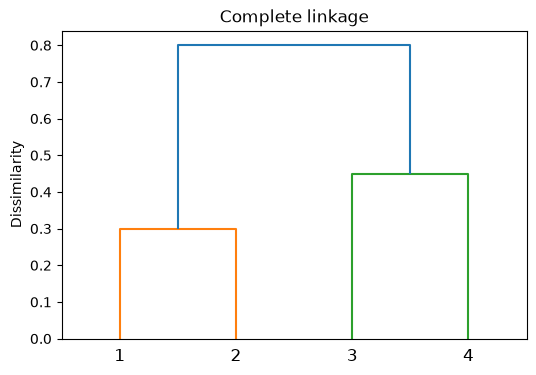

In [45]:
# Part (a)
complete = linkage(distances, method="complete")

fig, ax = plt.subplots(figsize=(6, 4))

dendrogram(complete, labels=["1", "2", "3", "4"], ax=ax)
ax.set_title("Complete linkage")
ax.set_ylabel("Dissimilarity")
plt.show()

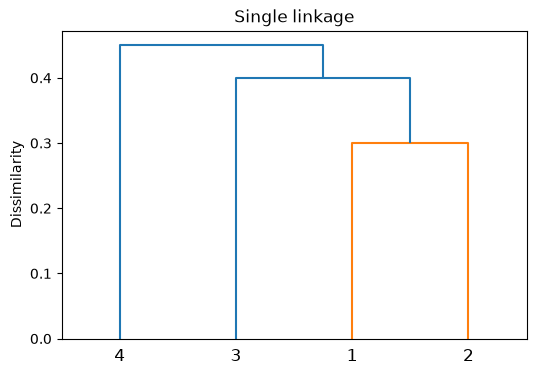

In [46]:
# Part (b)
single = linkage(distances, method="single")

fig, ax = plt.subplots(figsize=(6, 4))

dendrogram(single, labels=["1", "2", "3", "4"], ax=ax)
ax.set_title("Single linkage")
ax.set_ylabel("Dissimilarity")
plt.show()

* Part (c) If the complete-linkage dendrogram is cut to form two clusters then the observations that are in each cluster are {1,2} and {3,4}

* Part (d) As for a single-linkage dendrogram, cutting them would give {1,2,3} and {4}

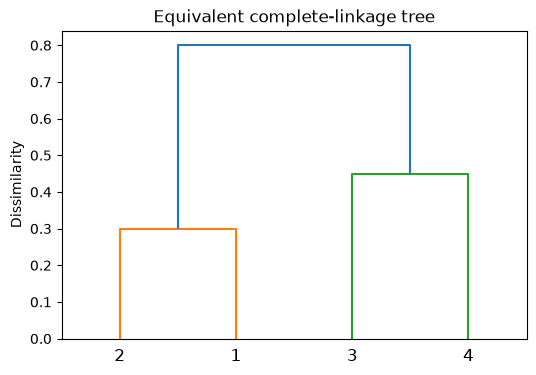

In [47]:
# Part (e)
complete_swapped = complete.copy()

complete_swapped[0, 0], complete_swapped[0, 1] = (
    complete_swapped[0, 1],
    complete_swapped[0, 0]
)

fig, ax = plt.subplots(figsize=(6, 4))

dendrogram(complete_swapped, labels=["1", "2", "3", "4"], ax=ax)
ax.set_title("Equivalent complete-linkage tree")
ax.set_ylabel("Dissimilarity")
plt.show()